In [1]:
import os, sys
cur_directory = os.getcwd()
project_folder = os.path.abspath(os.path.join(cur_directory, os.pardir, os.pardir))
save_directory = os.path.join(cur_directory, 'saved')
sys.path.append(os.path.join(project_folder, 'analysis-suite'))

In [2]:
import numpy as np
import matplotlib as mpl
from matplotlib import pyplot as plt
import analyses as als
import datasets as ds
import models as mds
import tools
from random import sample
from tqdm import tqdm
from argparse import Namespace
from time import gmtime, strftime
import pickle

In [3]:
mov_ind = 4

In [4]:
load_path = f'saved/M_latent_mov{mov_ind}.pkl'
M = ds.load_dataset(load_path)

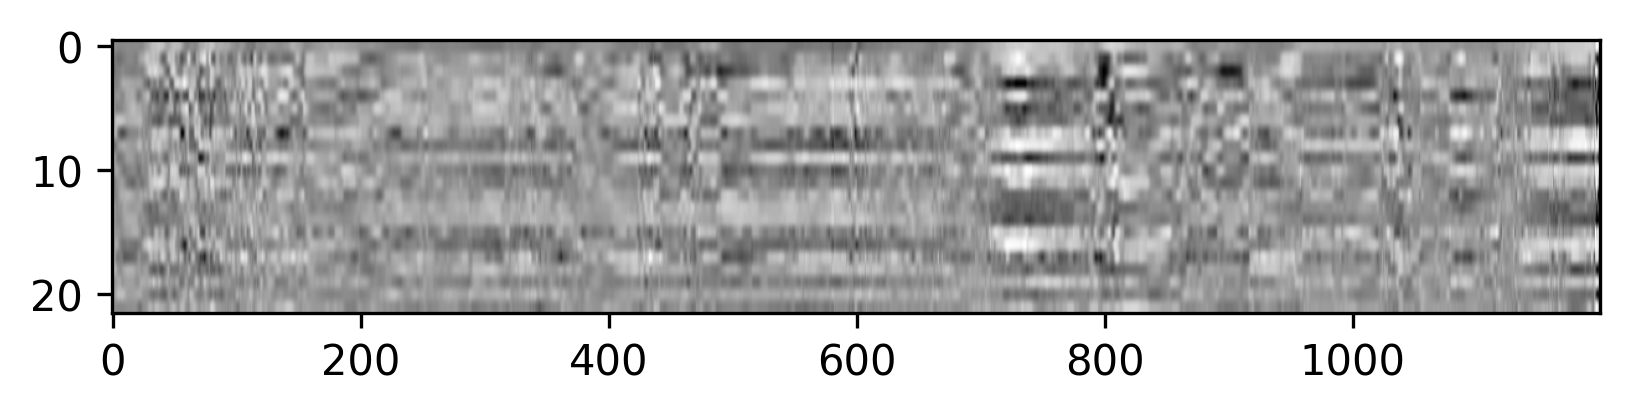

In [11]:
plt.subplots(dpi=300)
plt.imshow(M.X, cmap='Greys')
plt.gca().set_aspect(10)

# IB curve

Critic parameters decided using train/test validation below

## Params

In [ ]:
# K_array = np.arange(10) + 1
K_array=np.array([1,2,4,8,16,M.N])
N_training_repeats = 10
cg_params = {
    "order": 1,
}
critic_params = {
    "hidden_dim": 100,
    "embed_dim": 30,
    "layers": 2,
    "activation": "tanh",
}
opt_params = {"track_quantities": False, "quiet": True, "iterations": 50}
mi_measurement_params = {'quiet':True, 'batch_size':500, 'N_batches':500}

V_width = 1
V_E_buffer = 0
E_width = 1

train_fraction = 0.5
samp_keep = 1
# neuron_inds = np.sort(sample(list(np.arange(93)), k=50))

# Put variable names here for parameters we want saved.
experiment_configuration_variables = {'mi_measurement_params','meta_neuron_array', 'N_training_repeats', 'cg_params', 'critic_params', 'opt_params', 'V_width', 'V_E_buffer', 'E_width', 'train_fraction', 'samp_keep', 'neuron_inds'}

In [ ]:
K_array

array([ 1,  2,  4,  8, 16, 22])

## Prepare data

In [ ]:
M.reset()
# M.trim(20)  # remove first 20 frames from each trial
V, E = M.create_V_and_E_datasets(V_width, V_E_buffer, E_width, samp_keep=samp_keep)

## Run analysis

In [ ]:
experiment_dims = (len(K_array), N_training_repeats)
mi_averages_test = np.zeros(experiment_dims)
mi_averages_train = np.zeros(experiment_dims)
mi_stdevs_train = np.zeros(experiment_dims)
mi_stdevs_test = np.zeros(experiment_dims)

coarse_grainer_array = np.zeros(experiment_dims, dtype=object)
critic_function_array = np.zeros(experiment_dims, dtype=object)
train_points = np.zeros(experiment_dims, dtype=object)
test_points = np.zeros(experiment_dims, dtype=object)


for i, N_meta_neurons in tqdm(enumerate(K_array)):
    for training_repeat in range(N_training_repeats):
        coarse_grainer = mds.PolynomialLayer(output_dim=N_meta_neurons, **cg_params)
        critic_function = mds.SeparableCritic(**critic_params)

        # make training and test subsets
        V.reset()
        E.reset()
        current_train_points, current_test_points = tools.generate_train_test_indices(
            V.P, train_fraction
        )
        V.subset_points(current_train_points)
        E.subset_points(current_train_points)
        train_points[i, training_repeat] = current_train_points
        test_points[i, training_repeat] = current_test_points

        # Train current
        als.IB(
            X=V.X,
            Y=E.X,
            coarse_grainer=coarse_grainer,
            critic_function=critic_function,
            **opt_params
        )

        # Measure InfoNCE for train
        T_train = coarse_grainer(V.X.T).numpy().T
        mi_train = als.MI_NCE(
            X=T_train, Y=E.X, critic_function=critic_function, **mi_measurement_params
        )
        mi_averages_train[i, training_repeat] = mi_train["mi"]
        mi_stdevs_train[i, training_repeat] = mi_train["mi_stdev"]

        # Measure InfoNCE for test
        V.reset()
        E.reset()
        V.subset_points(current_test_points)
        E.subset_points(current_test_points)
        T_test = coarse_grainer(V.X.T).numpy().T
        mi_test = als.MI_NCE(
            X=T_test, Y=E.X, critic_function=critic_function, **mi_measurement_params
        )
        mi_averages_test[i, training_repeat] = mi_test["mi"]
        mi_stdevs_test[i, training_repeat] = mi_test["mi_stdev"]

        coarse_grainer_array[i, training_repeat] = coarse_grainer
        critic_function_array[i, training_repeat] = critic_function

6it [01:49, 18.25s/it]


In [ ]:
data = Namespace(**locals())

In [ ]:
average_test = np.average(data.mi_averages_test, axis=1)
average_train = np.average(data.mi_averages_train, axis=1)
trial_variance_test = np.diag(np.cov(data.mi_averages_test))
trial_variance_train = np.diag(np.cov(data.mi_averages_train))
full_stdevs_train = np.sqrt(np.sum(data.mi_stdevs_train**2, axis=1) + trial_variance_train)
full_stdevs_test = np.sqrt(np.sum(data.mi_stdevs_test**2, axis=1) + trial_variance_test)

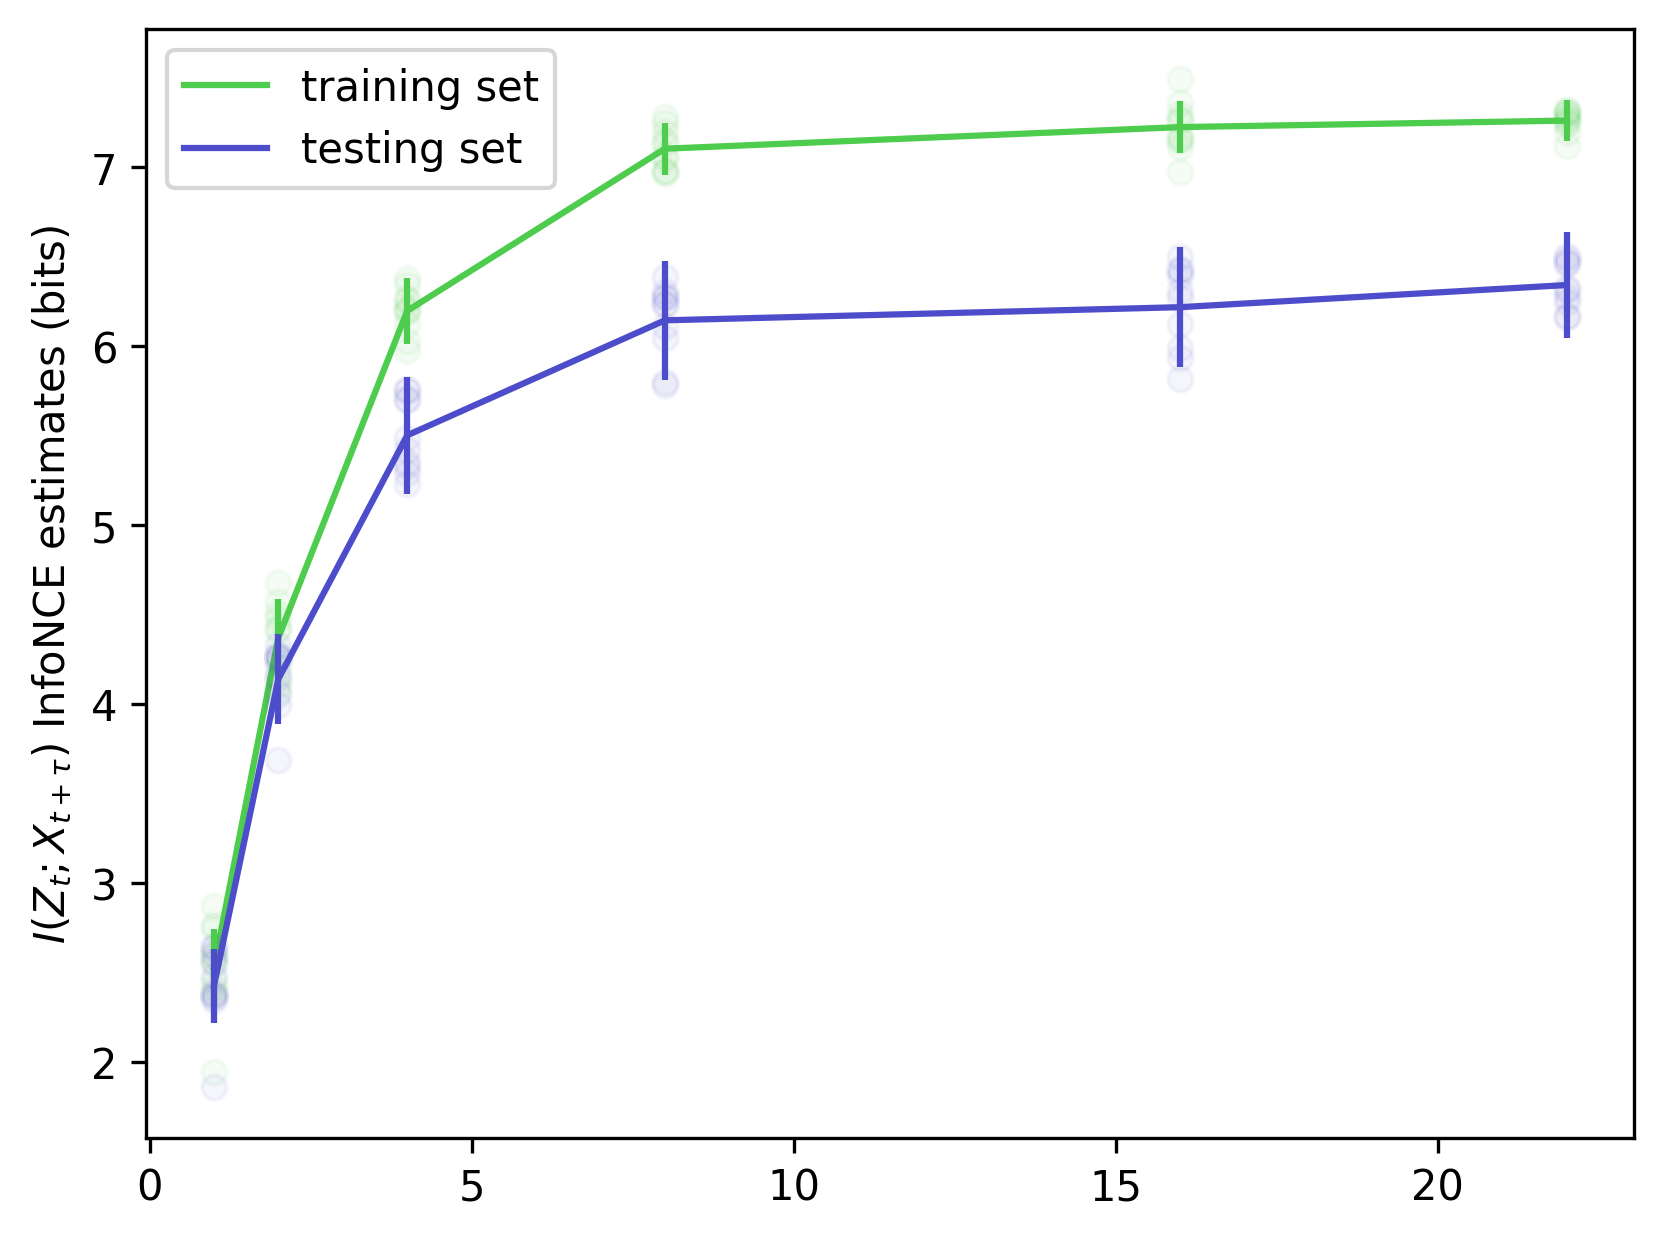

In [ ]:
x = data.K_array

c1 = 0.3
c2 = 0.8
alp = 0.05
plt.figure(dpi=300)
plt.plot(x, average_train/np.log(2), color=(c1,c2,c1), label='training set')
plt.plot(x, data.mi_averages_train/np.log(2),'o', color=(c1,c2,c1,alp))
plt.plot(x, average_test/np.log(2), color=(c1,c1,c2), label='testing set');
plt.plot(x, data.mi_averages_test/np.log(2),'o', color=(c1,c1,c2,alp))
plt.errorbar(x, average_train/np.log(2), yerr=full_stdevs_train, linestyle='', color=(c1,c2,c1))
plt.errorbar(x, average_test/np.log(2), yerr=full_stdevs_test, linestyle='', color=(c1,c1,c2))
# plt.ylim(ymin=0)
plt.ylabel(r'$I(Z_{t};X_{t+\tau})$ InfoNCE estimates (bits)')
plt.legend();

# Train/test validation - epochs

Test optimum seems to always be at 50 regardless of critic params

In [175]:
N_training_repeats = 1
iterations_array = np.array([1, 10, 20, 30, 50, 75, 100, 150])
cg_params = {
    "order": 1,
    "output_dim": M.N
}

critic_params = {
    "hidden_dim": 100,
    "embed_dim": 100,
    "layers": 2,
    "activation": "tanh",
}

# opt_params = {"track_quantities": False, "quiet": True, "iterations": 50}
opt_params = {"track_quantities": False, "quiet": True}
mi_measurement_params = {'quiet':True, 'batch_size':500, 'N_batches':500}

V_width = 1
V_E_buffer = 0
E_width = 1

train_fraction = 0.5
samp_keep = 1

## Prepare data

In [176]:
M.reset()
V, E = M.create_V_and_E_datasets(V_width, V_E_buffer, E_width, samp_keep=samp_keep)

## Run analysis

In [177]:
experiment_dims = (len(iterations_array), N_training_repeats,)
mi_averages_test = np.zeros(experiment_dims)
mi_averages_train = np.zeros(experiment_dims)
mi_stdevs_train = np.zeros(experiment_dims)
mi_stdevs_test = np.zeros(experiment_dims)

coarse_grainer_array = np.zeros(experiment_dims, dtype=object)
critic_function_array = np.zeros(experiment_dims, dtype=object)
train_points = np.zeros(experiment_dims, dtype=object)
test_points = np.zeros(experiment_dims, dtype=object)

for n, iterations in tqdm(enumerate(iterations_array)):
    for training_repeat in tqdm(range(N_training_repeats)):
        cur_inds = (n, training_repeat)
        coarse_grainer = mds.PolynomialLayer(**cg_params)
        critic_function = mds.SeparableCritic(**critic_params)

        # make training and test subsets
        V.reset()
        E.reset()
        current_train_points, current_test_points = tools.generate_train_test_indices(
            V.P, train_fraction
        )
        V.subset_points(current_train_points)
        E.subset_points(current_train_points)
        train_points[cur_inds] = current_train_points
        test_points[cur_inds] = current_test_points

        # Train current
        opt_params["iterations"] = iterations
        als.IB(
            X=V.X,
            Y=E.X,
            coarse_grainer=coarse_grainer,
            critic_function=critic_function,
            **opt_params
        )

        # Measure InfoNCE for train
        T_train = coarse_grainer(V.X.T).numpy().T
        mi_train = als.MI_NCE(
            X=T_train, Y=E.X, critic_function=critic_function, **mi_measurement_params
        )
        mi_averages_train[cur_inds] = mi_train["mi"]
        mi_stdevs_train[cur_inds] = mi_train["mi_stdev"]

        # Measure InfoNCE for test
        V.reset()
        E.reset()
        V.subset_points(current_test_points)
        E.subset_points(current_test_points)
        T_test = coarse_grainer(V.X.T).numpy().T
        mi_test = als.MI_NCE(
            X=T_test, Y=E.X, critic_function=critic_function, **mi_measurement_params
        )
        mi_averages_test[cur_inds] = mi_test["mi"]
        mi_stdevs_test[cur_inds] = mi_test["mi_stdev"]

        coarse_grainer_array[cur_inds] = coarse_grainer
        critic_function_array[cur_inds] = critic_function

100%|██████████| 1/1 [00:02<00:00,  2.16s/it]
8it [00:14,  1.83s/it]


In [178]:
mi_averages_test / np.log(2), mi_stdevs_test / np.log(2)

(array([[0.65294887],
        [3.88306551],
        [5.14862719],
        [5.91420158],
        [6.20433276],
        [4.54925862],
        [4.56764823],
        [0.25364461]]),
 array([[0.13435495],
        [0.11527196],
        [0.1186014 ],
        [0.1218603 ],
        [0.17561353],
        [0.29511057],
        [0.32954006],
        [0.67614185]]))

In [179]:
mi_averages_train / np.log(2), mi_stdevs_train / np.log(2)

(array([[0.74182635],
        [4.12693834],
        [5.58088406],
        [6.54774571],
        [7.38653279],
        [7.42977115],
        [7.7157791 ],
        [6.53851195]]),
 array([[0.06758324],
        [0.07991893],
        [0.05990167],
        [0.05474634],
        [0.04491873],
        [0.06731437],
        [0.06781927],
        [0.17284018]]))

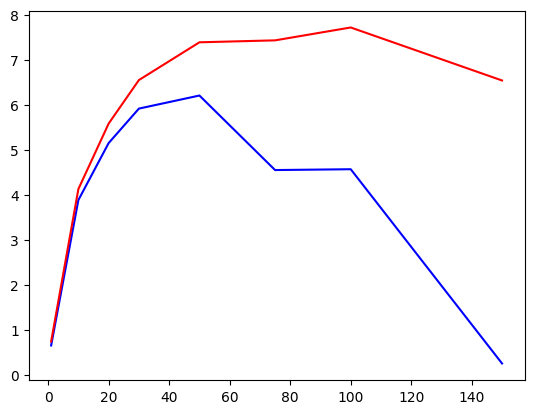

In [180]:
plt.plot(iterations_array, mi_averages_test/np.log(2), color='blue')
plt.plot(iterations_array, mi_averages_train/np.log(2), color='red')

# Train/test validation - hidden and embed dim

Best design seems to be layers=2, hidden_dim = 100, embed_dim = 40 (approx).

Notes:
- Embed dim seems to be sloppy
- Hidden dim seems to be best around 100-300, with 2 hidden layers
- With 4 hidden layers, best is between 10-200 
- With more than 2 hidden layers, wide layers give negative train and test 


In [236]:
N_training_repeats = 1
embed_dim_array = np.array([20, 30, 40, 50])
hidden_dim_array = np.array([10, 20, 40, 80, 160, 320, 640])
cg_params = {
    "order": 1,
    "output_dim": M.N
}

critic_params = {
    # "hidden_dim": 100,
    # "embed_dim": 100,
    "layers": 2,
    "activation": "tanh",
}

opt_params = {"track_quantities": False, "quiet": True, "iterations": 50}
# opt_params = {"track_quantities": False, "quiet": True}
mi_measurement_params = {'quiet':True, 'batch_size':500, 'N_batches':500}

V_width = 1
V_E_buffer = 0
E_width = 1

train_fraction = 0.5
samp_keep = 1

## Prepare data

In [237]:
M.reset()
V, E = M.create_V_and_E_datasets(V_width, V_E_buffer, E_width, samp_keep=samp_keep)

## Run analysis

In [238]:
experiment_dims = (len(embed_dim_array), len(hidden_dim_array), N_training_repeats,)
mi_averages_test = np.zeros(experiment_dims)
mi_averages_train = np.zeros(experiment_dims)
mi_stdevs_train = np.zeros(experiment_dims)
mi_stdevs_test = np.zeros(experiment_dims)

coarse_grainer_array = np.zeros(experiment_dims, dtype=object)
critic_function_array = np.zeros(experiment_dims, dtype=object)
train_points = np.zeros(experiment_dims, dtype=object)
test_points = np.zeros(experiment_dims, dtype=object)

for i, embed_dim in tqdm(enumerate(embed_dim_array)):
    for j, hidden_dim in enumerate(hidden_dim_array):
        for training_repeat in range(N_training_repeats):
            cur_inds = (i, j, training_repeat)
            coarse_grainer = mds.PolynomialLayer(**cg_params)
            critic_params["embed_dim"] = embed_dim
            critic_params["hidden_dim"] = hidden_dim
            critic_function = mds.SeparableCritic(**critic_params)

            # make training and test subsets
            V.reset()
            E.reset()
            current_train_points, current_test_points = tools.generate_train_test_indices(
                V.P, train_fraction
            )
            V.subset_points(current_train_points)
            E.subset_points(current_train_points)
            train_points[cur_inds] = current_train_points
            test_points[cur_inds] = current_test_points

            # Train current
            als.IB(
                X=V.X,
                Y=E.X,
                coarse_grainer=coarse_grainer,
                critic_function=critic_function,
                **opt_params
            )

            # Measure InfoNCE for train
            T_train = coarse_grainer(V.X.T).numpy().T
            mi_train = als.MI_NCE(
                X=T_train, Y=E.X, critic_function=critic_function, **mi_measurement_params
            )
            mi_averages_train[cur_inds] = mi_train["mi"]
            mi_stdevs_train[cur_inds] = mi_train["mi_stdev"]

            # Measure InfoNCE for test
            V.reset()
            E.reset()
            V.subset_points(current_test_points)
            E.subset_points(current_test_points)
            T_test = coarse_grainer(V.X.T).numpy().T
            mi_test = als.MI_NCE(
                X=T_test, Y=E.X, critic_function=critic_function, **mi_measurement_params
            )
            mi_averages_test[cur_inds] = mi_test["mi"]
            mi_stdevs_test[cur_inds] = mi_test["mi_stdev"]

            coarse_grainer_array[cur_inds] = coarse_grainer
            critic_function_array[cur_inds] = critic_function

0it [00:00, ?it/s]

4it [00:58, 14.61s/it]


In [241]:
mean_test = np.mean(mi_averages_test, axis=-1)
mean_train = np.mean(mi_averages_train, axis=-1)

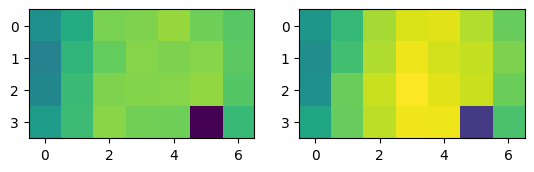

In [242]:
vmin = np.min(mean_test)
vmax = np.max(mean_train)
# vmin = 0
# vmax = 6

fig, ax = plt.subplots(ncols=2)
ax[0].imshow(mean_test, vmin=vmin, vmax=vmax)
ax[1].imshow(mean_train, vmin=vmin, vmax=vmax)

In [243]:
ed_test = np.mean(mean_test, axis=0)
ed_train = np.mean(mean_train, axis=0)

(0.0, 8.0)

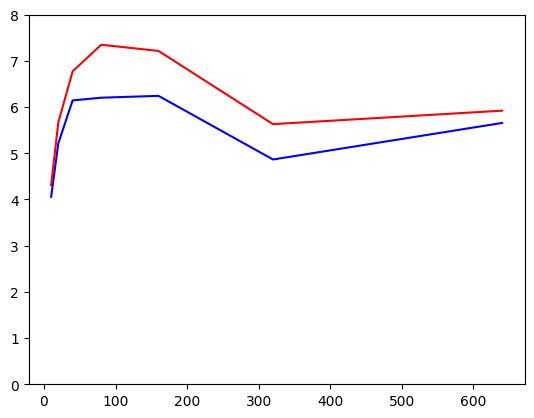

In [244]:
plt.plot(hidden_dim_array, ed_test/np.log(2), color='blue')
plt.plot(hidden_dim_array, ed_train/np.log(2), color='red')
plt.gca().set_ylim(0, 8)

In [245]:
ed_test / np.log(2), ed_train / np.log(2)

(array([4.0575218 , 5.21249519, 6.1440831 , 6.20312291, 6.24282452,
        4.86553363, 5.65613049]),
 array([4.31095626, 5.66595478, 6.77242592, 7.34963049, 7.21513438,
        5.63048776, 5.92216133]))